# Task 4: Visualise the Global Explainer Using a Summary Plot

This notebook follows the same basic steps as Tasks 2 and 3. It creates a SHAP Summary Plot to show which features are important across many predictions.

## 1. Install and import libraries

In [1]:
!pip install -q shap imbalanced-learn

In [2]:
import pandas as pd
import shap
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import RandomOverSampler

## 2. Upload the dataset

In [3]:
uploaded = files.upload()
file_name = next(iter(uploaded))
data = pd.read_csv(file_name)

print(data.shape)
data.head()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 3. Preprocess the data

In [4]:
categorical_cols = ['gender', 'ever_married', 'work_type',
                    'Residence_type', 'smoking_status']

encoded = pd.get_dummies(data[categorical_cols], prefix=categorical_cols)
data = pd.concat([encoded, data], axis=1)
data.drop(categorical_cols, axis=1, inplace=True)
data['bmi'] = data['bmi'].fillna(0)
data.drop(['id'], axis=1, inplace=True)

## 4. Split the data

In [5]:
X = data.drop('stroke', axis=1)
y = data['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=2021
)

## 5. Balance the training data

In [6]:
oversampler = RandomOverSampler(sampling_strategy='minority', random_state=2021)
X_train_balanced, y_train_balanced = oversampler.fit_resample(X_train, y_train)

## 6. Train the Random Forest model

In [7]:
model = RandomForestClassifier(random_state=42)
model.fit(X_train_balanced, y_train_balanced)

print('Model training completed.')

Model training completed.


## 7. Create the SHAP explainer

In [8]:
explainer = shap.TreeExplainer(model)

## 8. Calculate SHAP values

We use the test data to explain the model's predictions across many examples.

In [9]:
shap_values = explainer.shap_values(X_test)

print('SHAP values calculated.')

SHAP values calculated.


## 9. Show the Summary Plot

The Summary Plot gives a global view of feature importance. Features near the top have a stronger overall influence on the model's predictions.

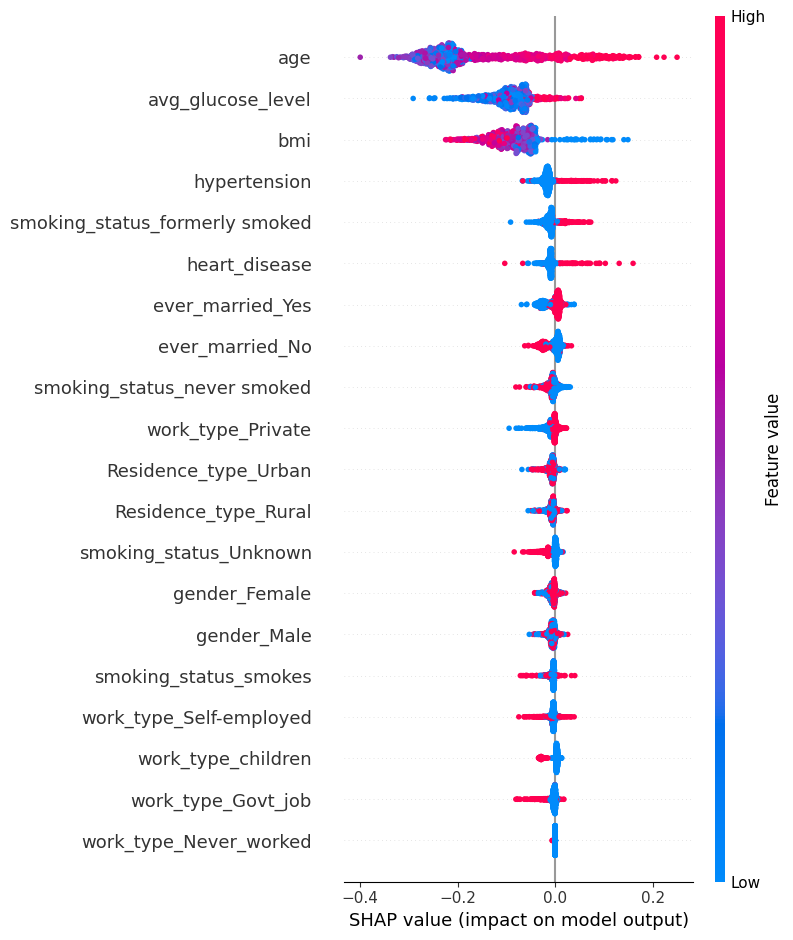

In [10]:
# For binary classification, use SHAP values for class 1 (stroke).
if isinstance(shap_values, list):
    values_for_stroke = shap_values[1]
elif len(shap_values.shape) == 3:
    values_for_stroke = shap_values[:, :, 1]
else:
    values_for_stroke = shap_values

shap.summary_plot(values_for_stroke, X_test, show=False)
plt.show()

## 10. Rank the features

The number for each feature is the average size of its SHAP value on the test set. A larger number means a stronger effect across patients. It does not by itself say whether the feature raises or lowers stroke probability.

In [ ]:
importance = abs(values_for_stroke).mean(axis=0)
importance = pd.Series(importance, index=X_test.columns)
print(importance.sort_values(ascending=False).head(10))

## Task 4 completed

The Summary Plot shows how the features influence the model's predictions across the test dataset.